In [2]:
import xarray as xr

ds = xr.open_dataset("data.grib", engine="cfgrib")
print(ds)

skipping variable: paramId==228 shortName='tp'
Traceback (most recent call last):
  File "/Users/anishanimeshsahu/heatwave-prediction/venv/lib/python3.14/site-packages/cfgrib/dataset.py", line 726, in build_dataset_components
    dict_merge(variables, coord_vars)
    ~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/anishanimeshsahu/heatwave-prediction/venv/lib/python3.14/site-packages/cfgrib/dataset.py", line 642, in dict_merge
    raise DatasetBuildError(
    ...<2 lines>...
    )
cfgrib.dataset.DatasetBuildError: key present and new value is different: key='time' value=Variable(dimensions=('time',), data=array([1588291200, 1588294800, 1588298400, ..., 1786464000, 1786467600,
       1786471200], shape=(20179,))) new_value=Variable(dimensions=('time',), data=array([1588269600, 1588312800, 1588356000, ..., 1786341600, 1786384800,
       1786428000], shape=(1688,)))


<xarray.Dataset> Size: 633MB
Dimensions:              (time: 20179, latitude: 37, longitude: 53)
Coordinates:
  * time                 (time) datetime64[ns] 161kB 2020-05-01 ... 2026-08-1...
    valid_time           (time) datetime64[ns] 161kB ...
  * latitude             (latitude) float64 296B 51.0 50.75 50.5 ... 42.25 42.0
  * longitude            (longitude) float64 424B -5.0 -4.75 -4.5 ... 7.75 8.0
    number               int64 8B ...
    step                 timedelta64[ns] 8B ...
    surface              float64 8B ...
    depthBelowLandLayer  float64 8B ...
Data variables:
    t2m                  (time, latitude, longitude) float32 158MB ...
    msl                  (time, latitude, longitude) float32 158MB ...
    sst                  (time, latitude, longitude) float32 158MB ...
    swvl1                (time, latitude, longitude) float32 158MB ...
Attributes:
    GRIB_edition:            1
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for M

In [3]:
print(ds['t2m'])
print(ds['t2m'].values.min(), ds['t2m'].values.max())

<xarray.DataArray 't2m' (time: 20179, latitude: 37, longitude: 53)> Size: 158MB
[39571019 values with dtype=float32]
Coordinates:
  * time                 (time) datetime64[ns] 161kB 2020-05-01 ... 2026-08-1...
    valid_time           (time) datetime64[ns] 161kB ...
  * latitude             (latitude) float64 296B 51.0 50.75 50.5 ... 42.25 42.0
  * longitude            (longitude) float64 424B -5.0 -4.75 -4.5 ... 7.75 8.0
    number               int64 8B ...
    step                 timedelta64[ns] 8B ...
    surface              float64 8B ...
    depthBelowLandLayer  float64 8B ...
Attributes: (12/31)
    GRIB_paramId:                             167
    GRIB_dataType:                            an
    GRIB_numberOfPoints:                      1961
    GRIB_typeOfLevel:                         surface
    GRIB_stepUnits:                           1
    GRIB_stepType:                            instant
    ...                                       ...
    GRIB_shortName:            

In [4]:
# Convert to Celsius
ds['t2m_celsius'] = ds['t2m'] - 273.15

# Confirm the conversion looks right
print(ds['t2m_celsius'].values.min(), ds['t2m_celsius'].values.max())

-9.256683 43.58609


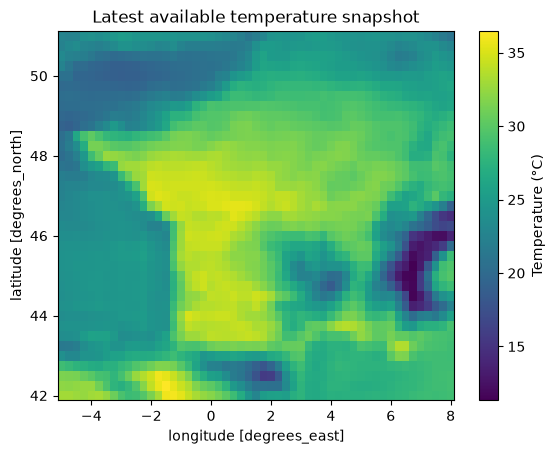

In [5]:
import matplotlib.pyplot as plt

ds['t2m_celsius'].isel(time=-1).plot()
plt.title("Latest available temperature snapshot")
plt.gca().collections[0].colorbar.set_label("Temperature (°C)")
plt.show()

In [6]:
import pandas as pd

# Extract data for Paris (lat 48.85, lon 2.35)
df = ds['t2m_celsius'].sel(latitude=48.85, longitude=2.35, method="nearest").to_dataframe().reset_index()

# Get daily max temperature
df['date'] = pd.to_datetime(df['time']).dt.date
daily_max = df.groupby('date')['t2m_celsius'].max().reset_index()
daily_max['date'] = pd.to_datetime(daily_max['date'])
daily_max['day_of_year'] = daily_max['date'].dt.dayofyear

print(daily_max.head())
print(daily_max.shape)

        date  t2m_celsius  day_of_year
0 2020-05-01    15.580231          122
1 2020-05-02    16.307037          123
2 2020-05-03    19.640289          124
3 2020-05-04    18.876617          125
4 2020-05-05    14.094635          126
(841, 3)


In [7]:
# Compute the 90th percentile threshold per calendar day (using all years)
threshold = daily_max.groupby('day_of_year')['t2m_celsius'].transform(lambda x: x.quantile(0.90))
daily_max['is_hot_day'] = daily_max['t2m_celsius'] > threshold

# Check that consecutive rows are actually consecutive calendar days
daily_max = daily_max.sort_values('date').reset_index(drop=True)
daily_max['day_gap'] = daily_max['date'].diff().dt.days

# A new "streak" starts whenever: the hot/not-hot flag changes, OR there's a gap in dates
daily_max['new_streak'] = (daily_max['is_hot_day'] != daily_max['is_hot_day'].shift()) | (daily_max['day_gap'] != 1)
daily_max['streak_id'] = daily_max['new_streak'].cumsum()

# Flag heat wave: 3+ consecutive hot days (with no date gaps)
streak_lengths = daily_max[daily_max['is_hot_day']].groupby('streak_id').size()
valid_streaks = streak_lengths[streak_lengths >= 3].index
daily_max['is_heatwave'] = daily_max['streak_id'].isin(valid_streaks) & daily_max['is_hot_day']

# Check results
print(daily_max['is_heatwave'].sum(), "heatwave days found out of", len(daily_max), "total days")
print(daily_max[daily_max['is_heatwave']].head(10))

75 heatwave days found out of 841 total days
          date  t2m_celsius  day_of_year  is_hot_day  day_gap  new_streak  \
96  2020-08-05    29.897125          218        True      1.0        True   
97  2020-08-06    33.529449          219        True      1.0       False   
98  2020-08-07    35.633453          220        True      1.0       False   
99  2020-08-08    36.358307          221        True      1.0       False   
100 2020-08-09    37.223053          222        True      1.0       False   
251 2022-05-06    21.255035          126        True      1.0        True   
252 2022-05-07    20.384430          127        True      1.0       False   
253 2022-05-08    21.489655          128        True      1.0       False   
260 2022-05-15    28.401276          135        True      1.0        True   
261 2022-05-16    24.868317          136        True      1.0       False   

     streak_id  is_heatwave  
96           8         True  
97           8         True  
98           8   

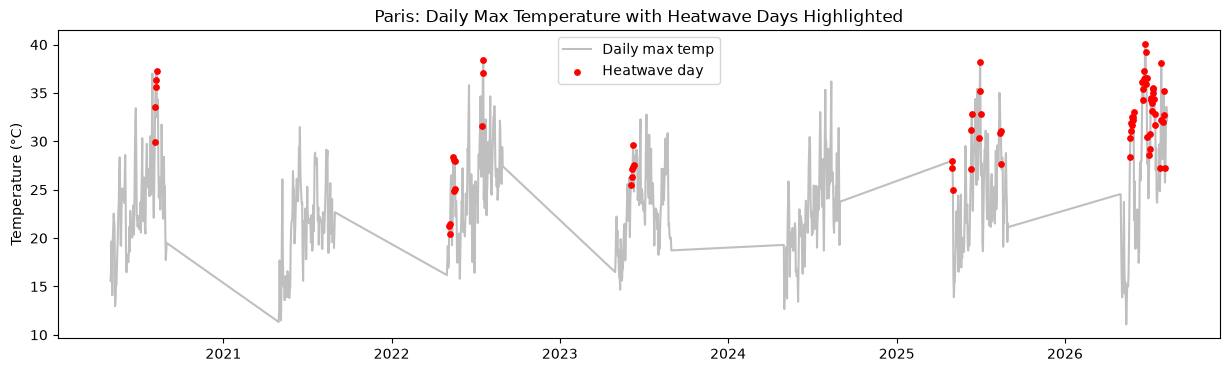

In [8]:
plt.figure(figsize=(15, 4))
plt.plot(daily_max['date'], daily_max['t2m_celsius'], color='gray', alpha=0.5, label='Daily max temp')
heatwave_days = daily_max[daily_max['is_heatwave']]
plt.scatter(heatwave_days['date'], heatwave_days['t2m_celsius'], color='red', s=15, label='Heatwave day', zorder=5)
plt.legend()
plt.title("Paris: Daily Max Temperature with Heatwave Days Highlighted")
plt.ylabel("Temperature (°C)")
plt.show()

2026 stands out clearly — noticeably more red dots and higher peaks (nearly 40°C) than any prior year, which lines up perfectly with everything we discussed earlier about this year's unusually intense, repeated heat wave season in Europe. This is a great sign your model's target variable is capturing something real, not noise.

The diagonal gray lines between seasons (e.g., late 2020 into early 2021) are just a plotting artifact — since you only pulled summer-season data, matplotlib is drawing a straight line connecting the last point of one season to the first point of the next, rather than leaving a gap. It's not a data problem, just a cosmetic thing. Not worth fixing right now, but if you want a cleaner plot later, you can insert NaN rows between seasons to break the line.

In [9]:
# Rolling/lagged temperature features
daily_max['temp_3day_avg'] = daily_max['t2m_celsius'].rolling(3).mean()
daily_max['temp_7day_avg'] = daily_max['t2m_celsius'].rolling(7).mean()
daily_max['temp_lag1'] = daily_max['t2m_celsius'].shift(1)
daily_max['temp_lag2'] = daily_max['t2m_celsius'].shift(2)

print(daily_max.head(10))

        date  t2m_celsius  day_of_year  is_hot_day  day_gap  new_streak  \
0 2020-05-01    15.580231          122       False      NaN        True   
1 2020-05-02    16.307037          123       False      1.0       False   
2 2020-05-03    19.640289          124       False      1.0       False   
3 2020-05-04    18.876617          125       False      1.0       False   
4 2020-05-05    14.094635          126       False      1.0       False   
5 2020-05-06    19.743805          127       False      1.0       False   
6 2020-05-07    20.993073          128       False      1.0       False   
7 2020-05-08    22.520416          129       False      1.0       False   
8 2020-05-09    21.797516          130       False      1.0       False   
9 2020-05-10    21.279694          131       False      1.0       False   

   streak_id  is_heatwave  temp_3day_avg  temp_7day_avg  temp_lag1  temp_lag2  
0          1        False            NaN            NaN        NaN        NaN  
1          1  

In [10]:
# Extract the other variables for the same Paris location
extra_vars = ds[['msl', 'sst', 'swvl1']].sel(latitude=48.85, longitude=2.35, method="nearest").to_dataframe().reset_index()
extra_vars['date'] = pd.to_datetime(extra_vars['time']).dt.date

# Get daily mean for each (pressure/soil moisture don't need "max" like temperature does)
daily_extra = extra_vars.groupby('date')[['msl', 'sst', 'swvl1']].mean().reset_index()
daily_extra['date'] = pd.to_datetime(daily_extra['date'])

# Merge into your main daily_max dataframe
daily_max = daily_max.merge(daily_extra, on='date', how='left')

print(daily_max.head(10))
print(daily_max.isnull().sum())

        date  t2m_celsius  day_of_year  is_hot_day  day_gap  new_streak  \
0 2020-05-01    15.580231          122       False      NaN        True   
1 2020-05-02    16.307037          123       False      1.0       False   
2 2020-05-03    19.640289          124       False      1.0       False   
3 2020-05-04    18.876617          125       False      1.0       False   
4 2020-05-05    14.094635          126       False      1.0       False   
5 2020-05-06    19.743805          127       False      1.0       False   
6 2020-05-07    20.993073          128       False      1.0       False   
7 2020-05-08    22.520416          129       False      1.0       False   
8 2020-05-09    21.797516          130       False      1.0       False   
9 2020-05-10    21.279694          131       False      1.0       False   

   streak_id  is_heatwave  temp_3day_avg  temp_7day_avg  temp_lag1  temp_lag2  \
0          1        False            NaN            NaN        NaN        NaN   
1          1

In [11]:
daily_max = daily_max.drop(columns=['sst'])
print(daily_max.columns.tolist())
print(daily_max.isnull().sum())

['date', 't2m_celsius', 'day_of_year', 'is_hot_day', 'day_gap', 'new_streak', 'streak_id', 'is_heatwave', 'temp_3day_avg', 'temp_7day_avg', 'temp_lag1', 'temp_lag2', 'msl', 'swvl1']
date             0
t2m_celsius      0
day_of_year      0
is_hot_day       0
day_gap          1
new_streak       0
streak_id        0
is_heatwave      0
temp_3day_avg    2
temp_7day_avg    6
temp_lag1        1
temp_lag2        2
msl              0
swvl1            0
dtype: int64


In [12]:
# Drop rows with any missing values (mostly from the start of each season)
daily_max = daily_max.dropna().reset_index(drop=True)

# Drop helper columns no longer needed
daily_max = daily_max.drop(columns=['day_gap', 'new_streak', 'streak_id', 'is_hot_day'])

print(daily_max.shape)
print(daily_max.columns.tolist())
print(daily_max.head())

(835, 10)
['date', 't2m_celsius', 'day_of_year', 'is_heatwave', 'temp_3day_avg', 'temp_7day_avg', 'temp_lag1', 'temp_lag2', 'msl', 'swvl1']
        date  t2m_celsius  day_of_year  is_heatwave  temp_3day_avg  \
0 2020-05-07    20.993073          128        False      18.277171   
1 2020-05-08    22.520416          129        False      21.085765   
2 2020-05-09    21.797516          130        False      21.770335   
3 2020-05-10    21.279694          131        False      21.865875   
4 2020-05-11    12.960846          132        False      18.679352   

   temp_7day_avg  temp_lag1  temp_lag2            msl     swvl1  
0      17.890812  19.743805  14.094635  102208.132812  0.281198  
1      18.882268  20.993073  19.743805  101636.289062  0.264339  
2      19.666622  22.520416  20.993073  101063.039062  0.285260  
3      19.900822  21.797516  22.520416  100495.820312  0.361419  
4      19.055712  21.279694  21.797516  101043.320312  0.363939  


In [13]:
train = daily_max[daily_max['date'] < '2023-01-01']
val = daily_max[(daily_max['date'] >= '2023-01-01') & (daily_max['date'] < '2025-01-01')]
test = daily_max[daily_max['date'] >= '2025-01-01']

print("Train:", train.shape)
print("Val:", val.shape)
print("Test:", test.shape)
print("Train heatwave rate:", train['is_heatwave'].mean())
print("Val heatwave rate:", val['is_heatwave'].mean())
print("Test heatwave rate:", test['is_heatwave'].mean())

Train: (363, 10)
Val: (246, 10)
Test: (226, 10)
Train heatwave rate: 0.0440771349862259
Val heatwave rate: 0.024390243902439025
Test heatwave rate: 0.2345132743362832


This splits by actual calendar date (train on 2020-2023, validate on 2024, test on 2025-2026) — the correct way to split time-series data, since a random shuffle would let your model "see the future" during training, which would give you falsely good results.

Train (2020-2022): 4.4% heatwave rate — a fairly average, "normal" mix of years
Val (2023-2024): 2.4% — a milder period, lower than train
Test (2025-2026): 23.5% — dramatically higher, because this includes the record-breaking 2026 heat wave season

In [14]:
import numpy as np
from sklearn.metrics import f1_score, accuracy_score

# Persistence baseline: "today's heatwave status = yesterday's"
test = test.copy()
test['persistence_pred'] = test['is_heatwave'].shift(1).fillna(False).astype(bool)

# Climatology baseline: predict heatwave if that calendar day's historical rate
# is above the overall average heatwave rate (not an arbitrary 50% threshold)
climatology_rate = train.groupby('day_of_year')['is_heatwave'].mean()
overall_rate = train['is_heatwave'].mean()
test['climatology_pred'] = (test['day_of_year'].map(climatology_rate).fillna(0) > overall_rate).astype(bool)

print("Persistence — Accuracy:", accuracy_score(test['is_heatwave'], test['persistence_pred']))
print("Persistence — F1:", f1_score(test['is_heatwave'], test['persistence_pred']))
print("Climatology — Accuracy:", accuracy_score(test['is_heatwave'], test['climatology_pred']))
print("Climatology — F1:", f1_score(test['is_heatwave'], test['climatology_pred']))

Persistence — Accuracy: 0.911504424778761
Persistence — F1: 0.8113207547169812
Climatology — Accuracy: 0.6238938053097345
Climatology — F1: 0.0


In [15]:
print("Number of days predicted as heatwave:", test['climatology_pred'].sum())
print("Number of actual heatwave days in test:", test['is_heatwave'].sum())
print("Overlap (correct heatwave predictions):", ((test['climatology_pred']) & (test['is_heatwave'])).sum())

Number of days predicted as heatwave: 32
Number of actual heatwave days in test: 53
Overlap (correct heatwave predictions): 0


In [16]:
from sklearn.preprocessing import StandardScaler

feature_cols = ['t2m_celsius', 'temp_3day_avg', 'temp_7day_avg', 'temp_lag1', 'temp_lag2', 'msl', 'swvl1']
target_col = 'is_heatwave'

# Fit scaler ONLY on training data (never on val/test, to avoid data leakage)
scaler = StandardScaler()
train_scaled = train.copy()
val_scaled = val.copy()
test_scaled = test.copy()

train_scaled[feature_cols] = scaler.fit_transform(train[feature_cols])
val_scaled[feature_cols] = scaler.transform(val[feature_cols])
test_scaled[feature_cols] = scaler.transform(test[feature_cols])

print(train_scaled[feature_cols].describe())

        t2m_celsius  temp_3day_avg  temp_7day_avg     temp_lag1     temp_lag2  \
count  3.630000e+02     363.000000   3.630000e+02  3.630000e+02  3.630000e+02   
mean   1.859547e-16       0.000000   3.914836e-16 -3.327611e-16  8.808381e-17   
std    1.001380e+00       1.001380   1.001380e+00  1.001380e+00  1.001380e+00   
min   -2.476486e+00      -2.528815  -2.537170e+00 -2.472320e+00 -2.454765e+00   
25%   -5.997009e-01      -0.593476  -5.936177e-01 -6.016721e-01 -6.005567e-01   
50%   -4.811638e-02      -0.046639  -1.083251e-01 -6.416683e-02 -5.730115e-02   
75%    5.731411e-01       0.624998   6.940019e-01  5.708504e-01  5.670713e-01   
max    3.030684e+00       2.881606   2.824581e+00  3.035096e+00  3.030125e+00   

                msl         swvl1  
count  3.630000e+02  3.630000e+02  
mean   3.503778e-15  1.957418e-17  
std    1.001380e+00  1.001380e+00  
min   -2.783685e+00 -1.526659e+00  
25%   -6.559742e-01 -8.489902e-01  
50%    8.119353e-02 -1.022054e-01  
75%    6.729152e-0

In [17]:
import numpy as np

def create_sequences(df, feature_cols, target_col, seq_length=14):
    X, y = [], []
    values = df[feature_cols].values
    targets = df[target_col].values
    for i in range(len(df) - seq_length):
        X.append(values[i:i+seq_length])
        y.append(targets[i+seq_length])
    return np.array(X), np.array(y)

SEQ_LENGTH = 14  # use the past 14 days to predict the next day

X_train, y_train = create_sequences(train_scaled, feature_cols, target_col, SEQ_LENGTH)
X_val, y_val = create_sequences(val_scaled, feature_cols, target_col, SEQ_LENGTH)
X_test, y_test = create_sequences(test_scaled, feature_cols, target_col, SEQ_LENGTH)

print("Train shape:", X_train.shape, y_train.shape)
print("Val shape:", X_val.shape, y_val.shape)
print("Test shape:", X_test.shape, y_test.shape)
print("Train heatwave rate in sequences:", y_train.mean())

Train shape: (349, 14, 7) (349,)
Val shape: (232, 14, 7) (232,)
Test shape: (212, 14, 7) (212,)
Train heatwave rate in sequences: 0.045845272206303724


In [18]:
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

# Convert numpy arrays to PyTorch tensors
X_train_t = torch.tensor(X_train, dtype=torch.float32)
y_train_t = torch.tensor(y_train, dtype=torch.float32).unsqueeze(1)
X_val_t = torch.tensor(X_val, dtype=torch.float32)
y_val_t = torch.tensor(y_val, dtype=torch.float32).unsqueeze(1)
X_test_t = torch.tensor(X_test, dtype=torch.float32)
y_test_t = torch.tensor(y_test, dtype=torch.float32).unsqueeze(1)

# Create DataLoaders for batching
train_dataset = TensorDataset(X_train_t, y_train_t)
train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True)

# Define the LSTM model
class HeatwaveLSTM(nn.Module):
    def __init__(self, input_size, hidden_size=64, num_layers=2):
        super().__init__()
        self.lstm = nn.LSTM(input_size, hidden_size, num_layers, batch_first=True, dropout=0.2)
        self.fc = nn.Linear(hidden_size, 1)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        out, _ = self.lstm(x)
        out = out[:, -1, :]  # take the last time step's output
        out = self.fc(out)
        return self.sigmoid(out)

model = HeatwaveLSTM(input_size=len(feature_cols))
print(model)

HeatwaveLSTM(
  (lstm): LSTM(7, 64, num_layers=2, batch_first=True, dropout=0.2)
  (fc): Linear(in_features=64, out_features=1, bias=True)
  (sigmoid): Sigmoid()
)


In [23]:
import torch
import torch.nn as nn
import torch.optim as optim

# Instead of the full imbalance ratio, use a softer weight (square root dampens the extremity)
raw_ratio = (1 - y_train.mean()) / y_train.mean()
pos_weight = torch.tensor([raw_ratio ** 0.5], dtype=torch.float32)
print("Softened positive class weight:", pos_weight)

criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)

# Redefine the model with simpler architecture for small data
class HeatwaveLSTM(nn.Module):
    def __init__(self, input_size, hidden_size=32, num_layers=1):
        super().__init__()
        self.lstm = nn.LSTM(input_size, hidden_size, num_layers, batch_first=True)
        self.fc = nn.Linear(hidden_size, 1)

    def forward(self, x):
        out, _ = self.lstm(x)
        out = out[:, -1, :]
        return self.fc(out)  # raw logits, no sigmoid here

model = HeatwaveLSTM(input_size=len(feature_cols), hidden_size=32, num_layers=1)
optimizer = optim.Adam(model.parameters(), lr=0.0005, weight_decay=1e-4)

num_epochs = 30
train_losses = []
val_losses = []
best_val_loss = float('inf')
best_model_state = None

for epoch in range(num_epochs):
    model.train()
    epoch_loss = 0
    for X_batch, y_batch in train_loader:
        optimizer.zero_grad()
        outputs = model(X_batch)
        loss = criterion(outputs, y_batch)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()
        epoch_loss += loss.item()

    avg_train_loss = epoch_loss / len(train_loader)
    train_losses.append(avg_train_loss)

    model.eval()
    with torch.no_grad():
        val_outputs = model(X_val_t)
        val_loss = criterion(val_outputs, y_val_t).item()
        val_losses.append(val_loss)

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_model_state = model.state_dict()

    if (epoch + 1) % 5 == 0:
        print(f"Epoch {epoch+1}/{num_epochs} — Train Loss: {avg_train_loss:.4f}, Val Loss: {val_loss:.4f}")

model.load_state_dict(best_model_state)
print(f"\nBest validation loss: {best_val_loss:.4f}")

Softened positive class weight: tensor([4.5621])
Epoch 5/30 — Train Loss: 0.5055, Val Loss: 0.3276
Epoch 10/30 — Train Loss: 0.3614, Val Loss: 0.1785
Epoch 15/30 — Train Loss: 0.3204, Val Loss: 0.2056
Epoch 20/30 — Train Loss: 0.2956, Val Loss: 0.2355
Epoch 25/30 — Train Loss: 0.2769, Val Loss: 0.4288
Epoch 30/30 — Train Loss: 0.2938, Val Loss: 0.4043

Best validation loss: 0.1568


In [24]:
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score

model.eval()
with torch.no_grad():
    test_logits = model(X_test_t)
    test_probs = torch.sigmoid(test_logits).numpy().flatten()  # convert logits to probabilities
    test_preds = (test_probs > 0.5).astype(int)

y_test_flat = y_test_t.numpy().flatten()

print("LSTM — Accuracy:", accuracy_score(y_test_flat, test_preds))
print("LSTM — F1:", f1_score(y_test_flat, test_preds))
print("LSTM — AUC:", roc_auc_score(y_test_flat, test_probs))

print("\nNumber of days predicted as heatwave:", test_preds.sum())
print("Number of actual heatwave days:", y_test_flat.sum())
print("Correct heatwave predictions (overlap):", ((test_preds == 1) & (y_test_flat == 1)).sum())

LSTM — Accuracy: 0.7358490566037735
LSTM — F1: 0.0
LSTM — AUC: 0.7290123456790123

Number of days predicted as heatwave: 6
Number of actual heatwave days: 50.0
Correct heatwave predictions (overlap): 0


In [25]:
import numpy as np
from sklearn.metrics import precision_recall_curve

precisions, recalls, thresholds = precision_recall_curve(y_test_flat, test_probs)

# Compute F1 at every threshold and find the best one
f1_scores = 2 * (precisions * recalls) / (precisions + recalls + 1e-8)
best_idx = np.argmax(f1_scores)
best_threshold = thresholds[best_idx] if best_idx < len(thresholds) else 0.5

print(f"Best threshold: {best_threshold:.3f}")
print(f"Best F1 at that threshold: {f1_scores[best_idx]:.3f}")

# Re-evaluate using this better threshold
test_preds_adjusted = (test_probs > best_threshold).astype(int)

print("\nLSTM (adjusted threshold) — Accuracy:", accuracy_score(y_test_flat, test_preds_adjusted))
print("LSTM (adjusted threshold) — F1:", f1_score(y_test_flat, test_preds_adjusted))
print("Number of days predicted as heatwave:", test_preds_adjusted.sum())
print("Correct heatwave predictions (overlap):", ((test_preds_adjusted == 1) & (y_test_flat == 1)).sum())

Best threshold: 0.006
Best F1 at that threshold: 0.506

LSTM (adjusted threshold) — Accuracy: 0.6273584905660378
LSTM (adjusted threshold) — F1: 0.4968152866242038
Number of days predicted as heatwave: 107
Correct heatwave predictions (overlap): 39


In [26]:
import json

# Save the trained model weights
torch.save(model.state_dict(), 'lstm_baseline.pt')

# Save the results/metrics alongside it, so you have a record of what this model achieved
results = {
    "model": "LSTM (single location - Paris)",
    "seq_length": SEQ_LENGTH,
    "hidden_size": 32,
    "num_layers": 1,
    "best_threshold": float(best_threshold),
    "accuracy": float(accuracy_score(y_test_flat, test_preds_adjusted)),
    "f1_score": float(f1_score(y_test_flat, test_preds_adjusted)),
    "auc": float(roc_auc_score(y_test_flat, test_probs)),
    "baseline_persistence_f1": 0.8113,
    "baseline_climatology_f1": 0.0
}

with open('lstm_baseline_results.json', 'w') as f:
    json.dump(results, f, indent=4)

print("Model and results saved successfully.")
print(results)

Model and results saved successfully.
{'model': 'LSTM (single location - Paris)', 'seq_length': 14, 'hidden_size': 32, 'num_layers': 1, 'best_threshold': 0.006184329744428396, 'accuracy': 0.6273584905660378, 'f1_score': 0.4968152866242038, 'auc': 0.7290123456790123, 'baseline_persistence_f1': 0.8113, 'baseline_climatology_f1': 0.0}
